# Robust nonlinear regression with piazzi

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cai4cai/torch-piazzi/blob/main/notebooks/robust_regression.ipynb)

This notebook follows the SciPy Cookbook example [Robust nonlinear regression in scipy](https://scipy-cookbook.readthedocs.io/items/robust_regression.html) (Nikolay Mayorov, BSD licence), with `piazzi` and PyTorch in place of `scipy.optimize.least_squares`.

We fit a model $f(t; x)$ to data $(t_i, y_i)$ by minimising a cost built from the residuals $r_i(x) = f(t_i; x) - y_i$. Ordinary least squares minimises $\frac12 \sum_i r_i^2$. It is the maximum-likelihood estimate when the errors are independent and Gaussian, but a few outliers can bias it badly.

A robust loss replaces $r^2$ with $\rho(r^2)$, where $\rho$ grows more slowly than linearly for large arguments. With a scale $C$ that separates inliers from outliers, the cost is

$$F(x) = \frac12 \sum_i C^2 \rho\!\left(\frac{r_i(x)^2}{C^2}\right),$$

which is the cost `scipy.optimize.least_squares` minimises with `loss=...` and `f_scale=C`.

## Setup

On Colab, the next cell installs `piazzi` from GitHub. Locally, install the notebook dependencies with `uv sync --group notebooks` (see the README).

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q git+https://github.com/cai4cai/torch-piazzi

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch

import piazzi

torch.set_default_dtype(torch.float64)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["legend.fontsize"] = 14
plt.rcParams["axes.labelsize"] = 14

## Robust loss functions

Each loss is a function $\rho(z)$ of the squared residual $z = r^2$, with $\rho(z) \approx z$ for small $z$. `piazzi` offers the same losses as `scipy.optimize.least_squares`:

| name | $\rho(z)$ |
|---|---|
| `linear` | $z$ |
| `huber` | $z$ if $z \le 1$, else $2\sqrt{z} - 1$ |
| `soft_l1` | $2(\sqrt{1 + z} - 1)$ |
| `cauchy` | $\log(1 + z)$ |
| `arctan` | $\arctan(z)$ |

`piazzi.LOSSES` maps each name to a function that returns $\rho(z)$, $\rho'(z)$ and $\rho''(z)$.

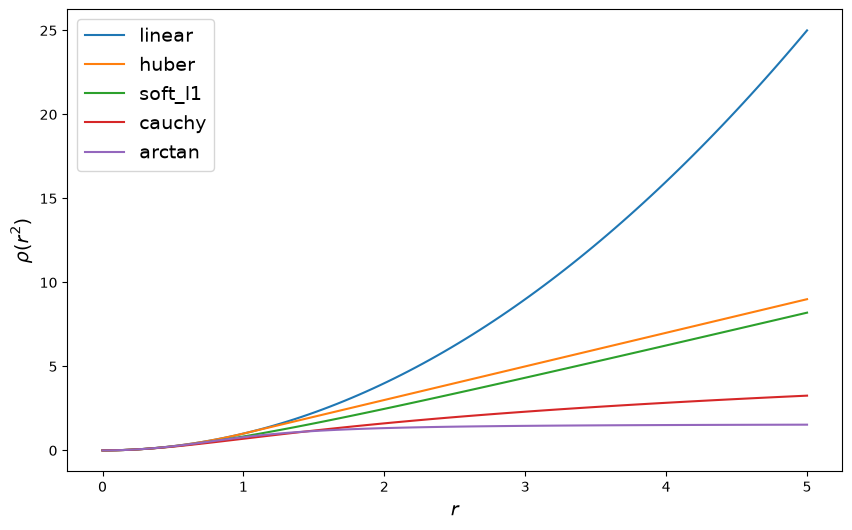

In [3]:
r = torch.linspace(0, 5, 100)
for name, loss in piazzi.LOSSES.items():
    rho, _, _ = loss(r**2)
    plt.plot(r, rho, label=name)
plt.xlabel("$r$")
plt.ylabel(r"$\rho(r^2)$")
plt.legend(loc="upper left");

The `cauchy` and `arctan` losses flatten out, so they attenuate outliers most strongly.

## Data

The model is a damped sine, $f(t; A, \sigma, \omega) = A e^{-\sigma t} \sin(\omega t)$. We generate the training data with the same NumPy random state as the cookbook, so the points (and their outliers) are identical.

In [4]:
def generate_data(t, A, sigma, omega, noise=0, n_outliers=0, random_state=0):
    y = A * np.exp(-sigma * t) * np.sin(omega * t)
    rnd = np.random.RandomState(random_state)
    error = noise * rnd.randn(t.size)
    outliers = rnd.randint(0, t.size, n_outliers)
    error[outliers] *= 35
    return y + error


A = 2
sigma = 0.1
omega = 0.1 * 2 * np.pi
x_true = np.array([A, sigma, omega])

noise = 0.1
t_min, t_max = 0, 30

t_train = np.linspace(t_min, t_max, 30)
y_train = generate_data(t_train, A, sigma, omega, noise=noise, n_outliers=4)

The residuals are a PyTorch function of the parameters $x = (A, \sigma, \omega)$. The starting point is $x_0 = (1, 1, 1)$, as in the cookbook.

In [5]:
t = torch.from_numpy(t_train)
y = torch.from_numpy(y_train)


def residuals(x):
    return x[0] * torch.exp(-x[1] * t) * torch.sin(x[2] * t) - y


x0 = torch.ones(3)

## Ordinary least squares

`piazzi.least_squares` mirrors `scipy.optimize.least_squares`: it takes the residual function and a starting point. It computes the Jacobian $J$ with forward-mode autodiff and solves the problem with Levenberg-Marquardt (`method="lm"`, the default) or Gauss-Newton (`method="gn"`).

In [6]:
res_lsq = piazzi.least_squares(residuals, x0, max_iter=200, step_tol=1e-8)
print(res_lsq.message, "| iterations:", res_lsq.n_iter)
print("x =", res_lsq.x.numpy())

predicted decrease below rounding noise | iterations: 62
x = [4.34045553 0.17254616 0.5310836 ]


## Robust least squares

As in SciPy, `loss` picks the loss and `f_scale` sets $C$. As in the cookbook, we use the `soft_l1` loss with $C = 0.1$, the noise level of the inliers.

In [7]:
res_robust = piazzi.least_squares(residuals, x0, loss="soft_l1", f_scale=0.1, max_iter=200, step_tol=1e-8)
print(res_robust.message, "| iterations:", res_robust.n_iter)
print("x =", res_robust.x.numpy())

step below step_tol | iterations: 39
x = [2.17468135 0.10381258 0.62766599]


With $z_i = r_i^2 / C^2$, the gradient of the cost is

$$\nabla F = J^\top (w \odot r), \qquad w_i = \rho'(z_i).$$

By default (`curvature="irls"`), `piazzi` uses $J^\top \operatorname{diag}(w) J$ as the curvature model. This is iteratively reweighted least squares (IRLS): each step is a weighted least-squares step, and points with large residuals get small weights. Ceres Solver uses the same model for these losses.

SciPy instead uses the weights $\max(\rho' + 2\rho'' z, \epsilon)$ (`curvature="scipy"`). These are more accurate for inliers, but for outliers they are floored at $\epsilon$. When most residuals start out as outliers, the curvature model is then nearly singular, which can stall Levenberg-Marquardt. Both models lead to the same minimiser.

`piazzi.robust_cost` computes the same cost as a differentiable scalar, so `piazzi.lbfgs_armijo` can also minimise it directly, with gradients from autograd and no Jacobian.

In [8]:
res_lbfgs = piazzi.lbfgs_armijo(
    lambda x: piazzi.robust_cost(residuals(x), loss="soft_l1", f_scale=0.1), x0, max_iter=500, step_tol=1e-9
)
print(res_lbfgs.message, "| iterations:", res_lbfgs.n_iter)
print("x =", res_lbfgs.x.numpy())

step below step_tol | iterations: 24
x = [2.17468136 0.10381258 0.62766599]


## Results

The ordinary least-squares fit is pulled away by the outliers. The robust fit is very close to the true model.

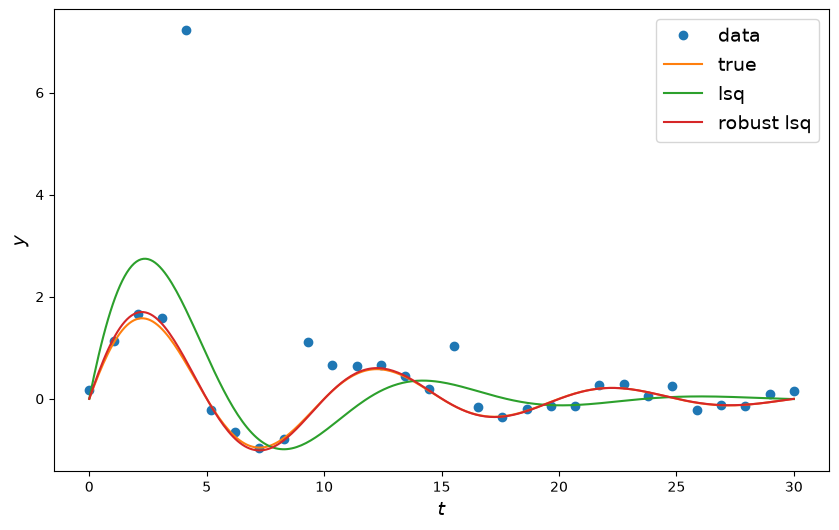

In [9]:
t_test = np.linspace(t_min, t_max, 300)
y_test = generate_data(t_test, A, sigma, omega)
y_lsq = generate_data(t_test, *res_lsq.x.numpy())
y_robust = generate_data(t_test, *res_robust.x.numpy())

plt.plot(t_train, y_train, "o", label="data")
plt.plot(t_test, y_test, label="true")
plt.plot(t_test, y_lsq, label="lsq")
plt.plot(t_test, y_robust, label="robust lsq")
plt.xlabel("$t$")
plt.ylabel("$y$")
plt.legend();

In [10]:
print(f"{'':>15} {'A':>8} {'sigma':>8} {'omega':>8}")
for name, x in [
    ("true", x_true),
    ("lsq", res_lsq.x.numpy()),
    ("robust (LM)", res_robust.x.numpy()),
    ("robust (L-BFGS)", res_lbfgs.x.numpy()),
]:
    print(f"{name:>15} " + " ".join(f"{v:8.4f}" for v in x))

                       A    sigma    omega
           true   2.0000   0.1000   0.6283
            lsq   4.3405   0.1725   0.5311
    robust (LM)   2.1747   0.1038   0.6277
robust (L-BFGS)   2.1747   0.1038   0.6277


## Comparison with SciPy

If SciPy is installed, we can check the fits against `scipy.optimize.least_squares`, as used in the cookbook.

In [11]:
try:
    from scipy.optimize import least_squares
except ImportError:
    print("SciPy is not installed; skipping the comparison.")
else:

    def fun(x, t, y):
        return x[0] * np.exp(-x[1] * t) * np.sin(x[2] * t) - y

    sp_lsq = least_squares(fun, np.ones(3), args=(t_train, y_train))
    sp_robust = least_squares(fun, np.ones(3), loss="soft_l1", f_scale=0.1, args=(t_train, y_train))
    print("lsq    scipy:", sp_lsq.x, " piazzi:", res_lsq.x.numpy())
    print("robust scipy:", sp_robust.x, " piazzi:", res_robust.x.numpy())
    print("max |difference|, robust:", np.abs(sp_robust.x - res_robust.x.numpy()).max())

lsq    scipy: [4.34066513 0.17255776 0.53103761]  piazzi: [4.34045553 0.17254616 0.5310836 ]
robust scipy: [2.17468133 0.10381258 0.62766599]  piazzi: [2.17468135 0.10381258 0.62766599]
max |difference|, robust: 2.6355142956902e-08


## Other losses

Every built-in loss works the same way. Here `cauchy` gets closest to the true parameters. `arctan` is bounded, so its cost is far from convex: from $x_0 = (1, 1, 1)$ it ends in a different local minimum.

In [12]:
for name in piazzi.LOSSES:
    res = piazzi.least_squares(residuals, x0, loss=name, f_scale=0.1, max_iter=200, step_tol=1e-8)
    err = np.abs(res.x.numpy() - x_true).max()
    print(f"{name:>8}: x = {res.x.numpy()}, max |x - x_true| = {err:.4f}")

  linear: x = [4.34045553 0.17254616 0.5310836 ], max |x - x_true| = 2.3405
   huber: x = [2.17570112 0.10313697 0.62853023], max |x - x_true| = 0.1757
 soft_l1: x = [2.17468135 0.10381258 0.62766599], max |x - x_true| = 0.1747
  cauchy: x = [2.0994557  0.09780574 0.63393193], max |x - x_true| = 0.0995
  arctan: x = [1.32771056 0.08834603 1.15850391], max |x - x_true| = 0.6723


A common remedy is to start a strongly robust loss from the solution of a milder one. Started from the `soft_l1` fit, `arctan` finds the right minimum.

In [13]:
res = piazzi.least_squares(residuals, res_robust.x, loss="arctan", f_scale=0.1, max_iter=200, step_tol=1e-8)
print(f"arctan from soft_l1: x = {res.x.numpy()}, max |x - x_true| = {np.abs(res.x.numpy() - x_true).max():.4f}")

arctan from soft_l1: x = [2.04252481 0.09190049 0.64254456], max |x - x_true| = 0.0425


## Custom losses

`loss` can also be any elementwise function $\rho(z)$ written in PyTorch. `piazzi` gets $\rho'$ and $\rho''$ from autograd. Here is the cube-root variant of `soft_l1` from SciPy's tests.

In [14]:
def cubic_soft_l1(z):
    return 3 * ((1 + z) ** (1 / 3) - 1)


res = piazzi.least_squares(residuals, x0, loss=cubic_soft_l1, f_scale=0.1, max_iter=200, step_tol=1e-8)
print(f"cubic_soft_l1: x = {res.x.numpy()}, max |x - x_true| = {np.abs(res.x.numpy() - x_true).max():.4f}")

cubic_soft_l1: x = [2.13479856 0.10112907 0.63021408], max |x - x_true| = 0.1348
